In [1]:
import numpy as np
from scipy.linalg import svd

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import scipy  as sp

# from scipy.linalg import fractional_matrix_power
# import sys
# sys.path.append('./utils')

# import h5py
import importlib
# import analysis
# import datasets as ds
import seaborn as sns

# %matplotlib ipympl
# %matplotlib inline
from deeptime.decomposition import VAMP, EDMD, DMD, KernelCCA, KernelEDMD
from deeptime.clustering import KMeans
from deeptime.decomposition import vamp_score_cv
import fastplotlib as fpl

%matplotlib inline

wgpu version from git (0.15.3) and __version__ (0.19.3) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.7.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post104+g63d70c0, need >=(0, 19, 0), <(0, 20, 0).
    To update, use e.g. `pip install -U wgpu`.


In [3]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

In [4]:
def generate_data(
        n_timepoints: int,
        n_components: int,
        noise: int,
        n_pixels: int | tuple[int, int],  # n_pixels PER component, if a tuple a random number of pixles within the range is used
        n_pixels_bg = 0,
        firing_prop = 0.05,
        interp_factor: int = 2,
) -> tuple[np.ndarray, np.ndarray]:
    """

    Parameters
    ----------
    n_timepoints: int

    n_components: int

    noise: int

    n_pixels: int, or (min, max) range
        n_pixels PER components, if (min, max) range is given then a random number of pixels within this range
        is used for each component

    n_pixels_bg: int

    interp_factor: int
        interpolation factor

    Returns
    -------
    np.ndarray, np.ndarray
        data [pixels, n_timepoints * interp_factor], truth labels: 1D array 0 is background

    """

    clean = np.zeros((n_components, n_timepoints * interp_factor)) + 0.01
    # print(clean)

    x = 0
    a_decay = 0.7
    a_rise = 5

    (0.01 / 5) * (5 / 0.01) * 5

    b = 0

    n_rise = 0

    spikes = list()

    for i in range(n_components):
        spikes.append((np.random.rand(n_timepoints) < firing_prop).astype(bool))

    for c_ix in range(n_components):
        for i in range(2, n_timepoints):
            if spikes[c_ix][i]:
                a = a_rise
                n_rise = 5
            elif n_rise > 0:
                if clean[c_ix, i - 1] > 1:
                    a = a_decay
                    n_rise = 0
                else:
                    a = a_rise
                    n_rise -= 1
            else:
                a = a_decay
            clean[c_ix, i] = (a * clean[c_ix, i - 1]) + (b * clean[c_ix, i - 2])# + (1 * spikes[c_ix][i])

        x_ = np.arange(0, n_timepoints * interp_factor)
        xp_ = np.linspace(0, n_timepoints * interp_factor, n_timepoints)
        clean[c_ix] = np.interp(x_, xp_, fp=clean[c_ix, :n_timepoints])

    n_timepoints *= interp_factor

    series = list()
    labels = list()

    for i in range(n_components):
        # determine number of pixels for this component
        if isinstance(n_pixels, int):
            _n_pixels_iter = n_pixels
        elif isinstance(n_pixels, tuple):
            _n_pixels_iter = np.random.randint(low=n_pixels[0], high=n_pixels[1])

        for j in range(_n_pixels_iter):
            series.append(clean[i] + np.random.normal(scale=noise, size=n_timepoints))
            labels.append(i + 1)

    # series = np.vstack(series)

    bg_pixels = [np.random.normal(scale=noise, size=n_timepoints) for i in range(n_pixels_bg)]
    series = np.vstack([*series, *bg_pixels])
    labels = np.array([*labels, *[0 for i in range(len(bg_pixels))]])

    return series, labels

In [5]:
n_components = 2

In [6]:
np.random.seed(0)
X, _ = generate_data(
    n_timepoints=250,
    n_components=n_components,
    noise=0.01,
    n_pixels=1,
    n_pixels_bg=0,
    interp_factor=2,
    firing_prop=0.05,
)

In [7]:
X.shape

(2, 500)

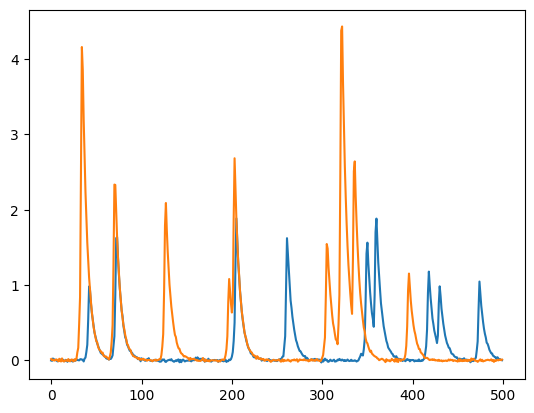

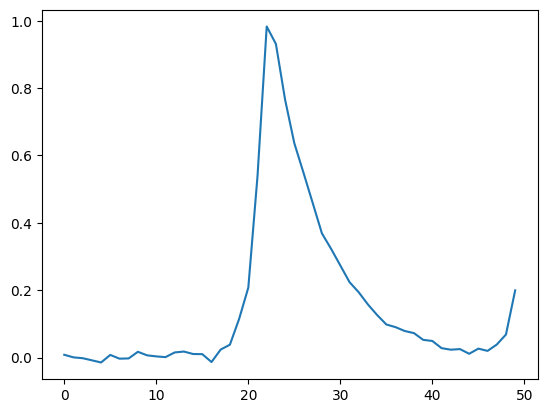

In [8]:
plt.plot(X[0])
plt.plot(X[1])
plt.show()
plt.plot(X.ravel()[20:70])

In [9]:
from scipy import linalg

Stacking

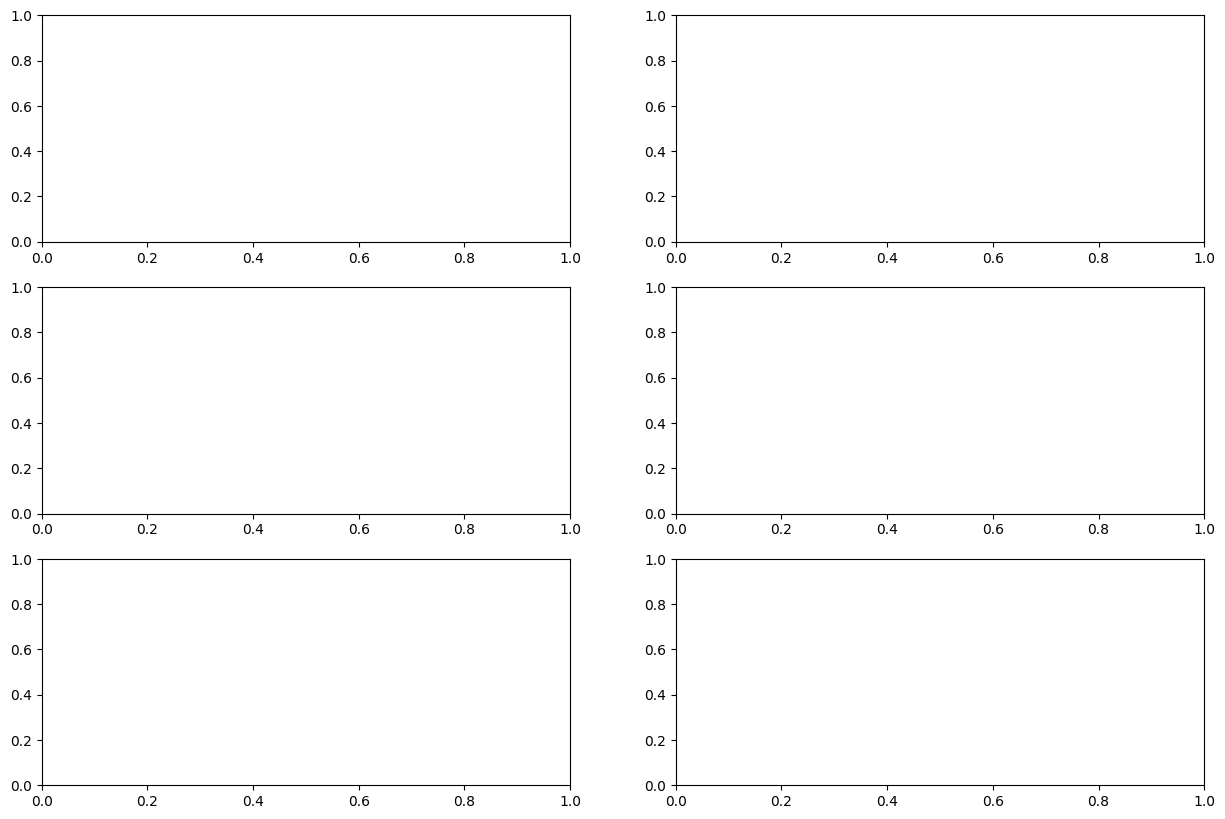

In [28]:
w = 2

Ys = list()
Ps = list()
Fs = list()

fig, axs = plt.subplots(3, n_components, figsize=(15, 10))

for i in range(n_components):
    y = linalg.hankel(X[i, :w], X[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)
        
    # sns.heatmap(y, ax=axs[0, i])
    # axs[0, i].set_title(f"$Y_{i}$")

    # sns.heatmap(p, ax=axs[1, i])
    # axs[1, i].set_title(f"$P_{i}$")

    # sns.heatmap(f, ax=axs[2, i])
    # axs[2, i].set_title(f"$F_{i}$")

# plt.tight_layout()

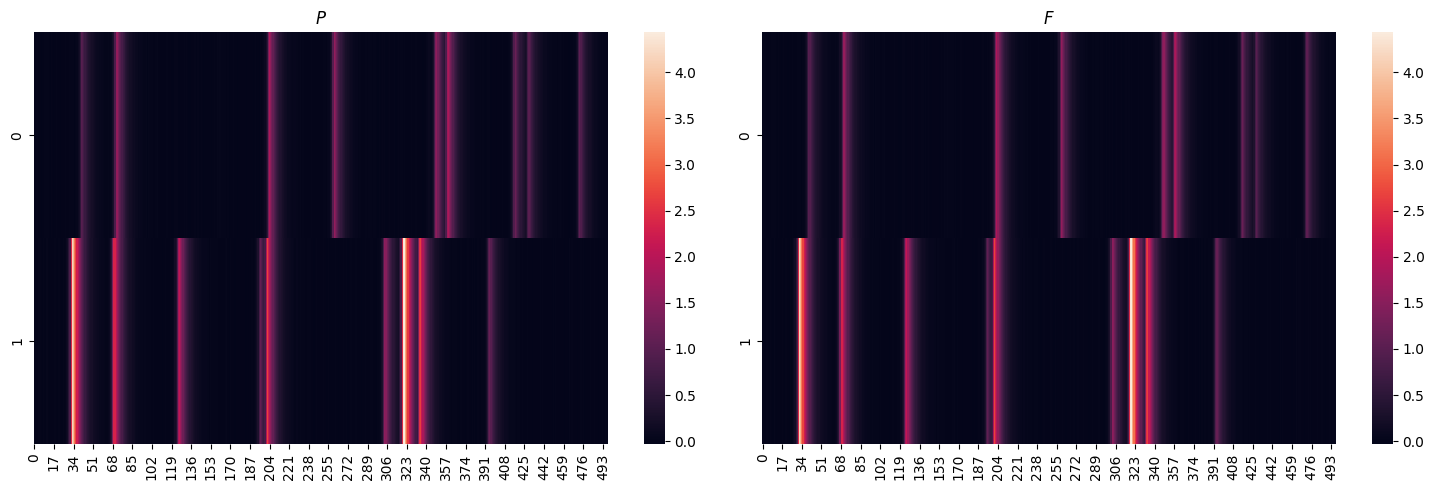

In [30]:
P = np.vstack(Ps)
F = np.vstack(Fs)

fig, axs = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(P, ax=axs[0])
axs[0].set_title(f"$P$")

sns.heatmap(F, ax=axs[1])
axs[1].set_title(f"$F$")
fig.tight_layout()
plt.show()

Interlacing

In [33]:
w = 2

Ys = list()
Ps = list()
Fs = list()

# fig, axs = plt.subplots(3, series.shape[0], figsize=(20, 10))

for i in range(X.shape[0]):
    y = linalg.hankel(X[i, :w], X[i, w:])
    p = np.flipud(y[:int(w / 2)])
    f = y[int(w / 2):]

    Ys.append(y)
    Ps.append(p)
    Fs.append(f)

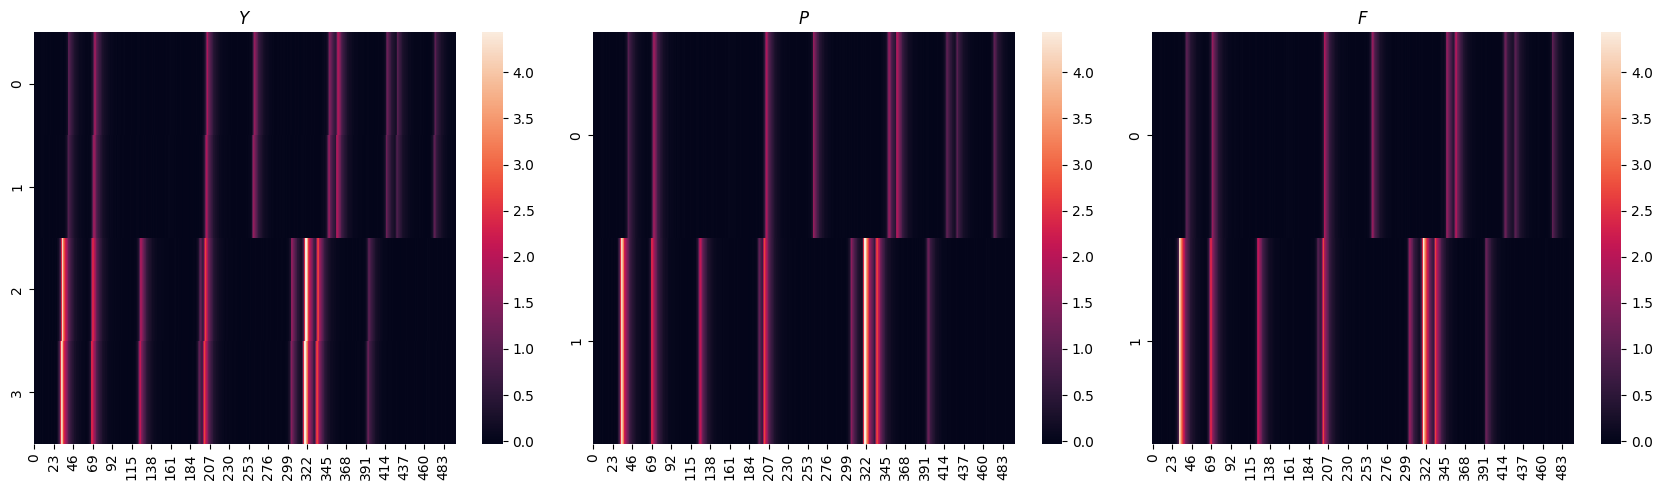

In [35]:
P_F_shape = (int(w / 2) * X.shape[0], X.shape[1] - w)

Y = np.vstack(Ys)
P = np.zeros(P_F_shape)
F = np.zeros(P_F_shape)

for i in range(X.shape[0]):
    P[i::X.shape[0]] = Ps[i]
    F[i::X.shape[0]] = Fs[i]

fig, axs = plt.subplots(1, 3, figsize=(17, 5))

sns.heatmap(Y, ax=axs[0])
axs[0].set_title(f"$Y$")

sns.heatmap(P, ax=axs[1])
axs[1].set_title(f"$P$")

sns.heatmap(F, ax=axs[2])
axs[2].set_title(f"$F$")
fig.tight_layout()
plt.show()

<Axes: >

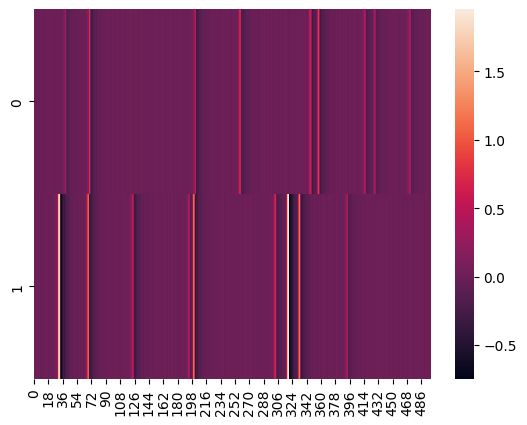

In [37]:
sns.heatmap(F - P)

In [ ]:
(P @ P.T)